# Q-Learning — Aprendizado por Reforço

> **Versão completa.** Todo o código já está preenchido: rode as células em ordem (Shift + Enter) e acompanhe os gráficos. A regra do Q-Learning está na seção 5 (função `atualizar_q`).

No MDP, sabíamos as **probabilidades de transição** P(s'|s,a).  
No **Q-Learning**, o agente **não sabe nada sobre o ambiente** — ele aprende tentando e errando.

| | MDP (Value Iteration) | Q-Learning |
|---|---|---|
| Conhece o ambiente? | ✅ Sim | ❌ Não |
| Como aprende? | Cálculo matemático | Tentativa e erro |
| O que armazena? | V(s) — valor dos estados | Q(s,a) — valor de cada ação em cada estado |

### A ideia central

O agente mantém uma tabela **Q(s, a)** que responde:
> *"Se eu estou no estado `s` e executo a ação `a`, qual recompensa total posso esperar?"*

### A equação de atualização (Bellman para Q-Learning)

$$Q(s, a) \leftarrow Q(s, a) + \alpha \Big[ r + \gamma \cdot \max_{a'} Q(s', a') - Q(s, a) \Big]$$

| Símbolo | Nome | Significado |
|---|---|---|
| α (alpha) | Taxa de aprendizado | Quanto o agente atualiza cada experiência nova |
| γ (gamma) | Fator de desconto | Quanto o agente valoriza recompensas futuras |
| r | Recompensa | Feedback imediato do ambiente |
| max Q(s',a') | Melhor Q do próximo estado | "O melhor que posso fazer daqui pra frente" |
| alvo − Q(s,a) | Erro TD | Diferença entre o que aconteceu (alvo) e o que esperava |

---
## 1. Importações

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import random

# Seed para reprodutibilidade
random.seed(42)
np.random.seed(42)

---
## 2. O Ambiente — Labirinto com Paredes e Armadilhas

O labirinto tem 3 tipos de células:

| Símbolo | Tipo | Recompensa |
|---|---|---|
| `·` | Livre | -1 (penalidade por passo) |
| `█` | Parede | Bloqueado |
| `☠` | Armadilha | -10 (grande penalidade) |
| `★` | Objetivo | +20 (grande recompensa) |

A penalidade por passo (-1) incentiva o agente a encontrar o **caminho mais curto**.

In [2]:
# Definição do labirinto
# 0=livre  1=parede  2=armadilha  3=objetivo
MAZE = np.array([
    [0, 0, 0, 1, 0, 0, 0],
    [0, 1, 0, 1, 0, 1, 0],
    [0, 1, 0, 0, 0, 1, 0],
    [0, 0, 0, 1, 2, 0, 0],
    [1, 1, 0, 1, 0, 1, 0],
    [0, 0, 0, 0, 0, 0, 2],
    [0, 1, 1, 1, 0, 0, 3],
])

ROWS, COLS = MAZE.shape
START = (0, 0)  # Canto superior esquerdo
GOAL  = (6, 6)  # Canto inferior direito ★

# Recompensas
REWARDS = {
    0: -1,   # Livre: penalidade por passo
    2: -10,  # Armadilha
    3: +20,  # Objetivo
}

# Ações: 0=cima, 1=baixo, 2=esquerda, 3=direita
ACTIONS = [0, 1, 2, 3]
ACTION_NAMES   = {0:'Cima', 1:'Baixo', 2:'Esquerda', 3:'Direita'}
ACTION_ARROWS  = {0:'↑',    1:'↓',    2:'←',         3:'→'}
ACTION_DELTAS  = {0:(-1,0), 1:(1,0),  2:(0,-1),       3:(0,1)}

print(f'Labirinto: {ROWS}x{COLS}')
print(f'Início: {START}  |  Objetivo: {GOAL}')
print(f'Células livres: {np.sum(MAZE == 0)}')
print(f'Paredes: {np.sum(MAZE == 1)}')
print(f'Armadilhas: {np.sum(MAZE == 2)}')

Labirinto: 7x7
Início: (0, 0)  |  Objetivo: (6, 6)
Células livres: 32
Paredes: 14
Armadilhas: 2


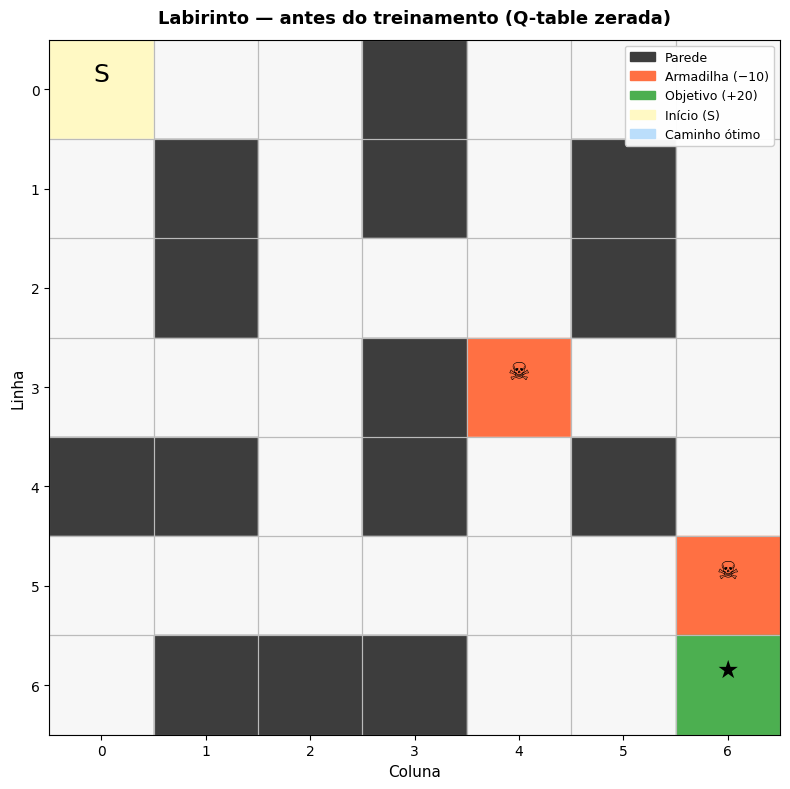

In [3]:
# @title Função de desenho do labirinto (rode e siga em frente)
def plot_maze(Q=None, episode=None, path=None, title=None):
    """
    Visualiza o labirinto.
    - Q      : Q-table (se fornecida, mostra a política aprendida)
    - path   : lista de (row, col) para destacar o caminho
    - title  : título do gráfico
    """
    fig, ax = plt.subplots(figsize=(8, 8))
    CELL_ICONS = {0: '', 1: '', 2: '☠', 3: '★'}
    CELL_COLORS = {
        0: '#f7f7f7',   # Livre
        1: '#3d3d3d',   # Parede
        2: '#FF7043',   # Armadilha
        3: '#4CAF50',   # Objetivo
    }

    for r in range(ROWS):
        for c in range(COLS):
            cell_type = MAZE[r, c]
            color = CELL_COLORS[cell_type]

            # Destaque do caminho
            if path and (r, c) in path and cell_type == 0:
                color = '#BBDEFB'
            if (r, c) == START:
                color = '#FFF9C4'

            ax.add_patch(plt.Rectangle((c, ROWS - r - 1), 1, 1,
                                       color=color, zorder=1))
            ax.add_patch(plt.Rectangle((c, ROWS - r - 1), 1, 1,
                                       fill=False, edgecolor='#bbbbbb',
                                       linewidth=0.8, zorder=2))

            # Ícone da célula
            icon = CELL_ICONS[cell_type]
            if (r, c) == START:
                icon = 'S'
            if icon:
                ax.text(c + 0.5, ROWS - r - 0.35, icon,
                        ha='center', va='center', fontsize=18, zorder=4)

            # Política aprendida (seta + valor Q)
            if Q is not None and cell_type == 0 and (r, c) != START and np.any(Q[r, c] != 0):
                best_a = np.argmax(Q[r, c])
                best_q = np.max(Q[r, c])
                ax.text(c + 0.5, ROWS - r - 0.55, ACTION_ARROWS[best_a],
                        ha='center', va='center', fontsize=20,
                        color='#1565C0', fontweight='bold', zorder=3)
                ax.text(c + 0.5, ROWS - r - 0.85, f'{best_q:.1f}',
                        ha='center', va='center', fontsize=8,
                        color='#888888', zorder=3)

            # Caminho com pontos
            if path and (r, c) in path:
                ax.plot(c + 0.5, ROWS - r - 0.5, 'o',
                        color='#1565C0', markersize=8, zorder=5, alpha=0.6)

    ax.set_xlim(0, COLS)
    ax.set_ylim(0, ROWS)
    ax.set_xticks(np.arange(COLS) + 0.5)
    ax.set_yticks(np.arange(ROWS) + 0.5)
    ax.set_xticklabels(range(COLS))
    ax.set_yticklabels(range(ROWS - 1, -1, -1))
    ax.set_xlabel('Coluna', fontsize=11)
    ax.set_ylabel('Linha', fontsize=11)

    ep_str = f' — Episódio {episode}' if episode is not None else ''
    ax.set_title((title or 'Labirinto') + ep_str, fontsize=13, fontweight='bold', pad=12)

    legend = [
        mpatches.Patch(color='#3d3d3d', label='Parede'),
        mpatches.Patch(color='#FF7043', label='Armadilha (−10)'),
        mpatches.Patch(color='#4CAF50', label='Objetivo (+20)'),
        mpatches.Patch(color='#FFF9C4', label='Início (S)'),
        mpatches.Patch(color='#BBDEFB', label='Caminho ótimo'),
    ]
    ax.legend(handles=legend, loc='upper right', fontsize=9, framealpha=0.95)
    plt.tight_layout()
    plt.show()


# Mostra o labirinto antes do treinamento
plot_maze(title='Labirinto — antes do treinamento (Q-table zerada)')

---
## 3. Lógica do Ambiente

O ambiente responde a ações com: `(novo_estado, recompensa, chegou_ao_fim?)`

In [4]:
def step(state, action):
    """
    Executa uma ação no ambiente.

    Retorna:
        (next_state, reward, done)
    """
    r, c = state
    dr, dc = ACTION_DELTAS[action]
    nr, nc = r + dr, c + dc

    # Verifica limites e paredes — se bater, fica no lugar
    if nr < 0 or nr >= ROWS or nc < 0 or nc >= COLS or MAZE[nr, nc] == 1:
        nr, nc = r, c

    next_state = (nr, nc)
    cell_type  = MAZE[nr, nc]
    reward     = REWARDS.get(cell_type, -1)
    done       = (next_state == GOAL) or (cell_type == 2)  # Chegou ou caiu em armadilha

    return next_state, reward, done


# Teste rápido
s = (0, 0)
print('Teste do ambiente a partir do estado inicial (0,0):')
for a in ACTIONS:
    ns, r, d = step(s, a)
    print(f'  Ação: {ACTION_NAMES[a]:9s} → próximo estado: {ns}  | recompensa: {r:+d}  | fim: {d}')

Teste do ambiente a partir do estado inicial (0,0):
  Ação: Cima      → próximo estado: (0, 0)  | recompensa: -1  | fim: False
  Ação: Baixo     → próximo estado: (1, 0)  | recompensa: -1  | fim: False
  Ação: Esquerda  → próximo estado: (0, 0)  | recompensa: -1  | fim: False
  Ação: Direita   → próximo estado: (0, 1)  | recompensa: -1  | fim: False


---
## 4. Estratégia ε-greedy — Explorar vs. Explotar

Este é o coração do Q-Learning: como o agente decide o que fazer?

```
Com probabilidade ε  → EXPLORAR   (ação aleatória — descobre coisas novas)
Com probabilidade 1-ε → EXPLOTAR  (melhor ação conhecida — usa o que aprendeu)
```

**ε decai ao longo do tempo:** no início o agente explora muito (ε alto),  
e vai se tornando mais confiante conforme aprende (ε diminui).

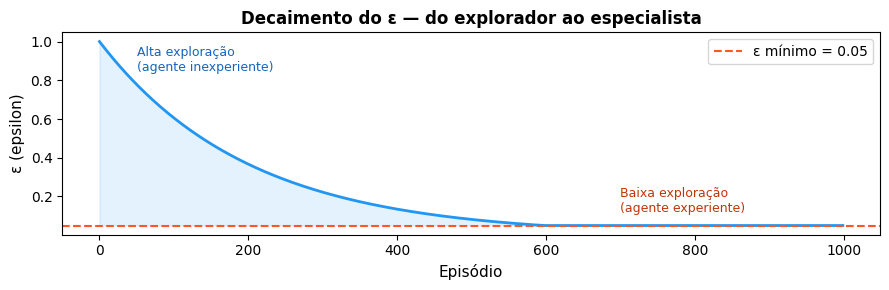

In [5]:
# ======================================================================
# 📚 NA AULA · ε-GREEDY: explorar (ação aleatória) × explotar (melhor ação)
# ======================================================================
def choose_action(state, Q, epsilon):
    """
    Estratégia ε-greedy:
    - Com prob. ε  → ação aleatória (exploração)
    - Com prob. 1-ε → melhor ação na Q-table (explotação)
    """
    if random.random() < epsilon:
        return random.choice(ACTIONS)          # Exploração
    r, c = state
    melhores = np.flatnonzero(Q[r, c] == Q[r, c].max())
    return int(random.choice(list(melhores)))  # Explotação (empate → sorteia entre as melhores)


# Visualizando o decaimento do epsilon
eps_inicio = 1.0
eps_minimo = 0.05
eps_decay  = 0.995

epsilons = []
e = eps_inicio
for _ in range(1000):
    epsilons.append(e)
    e = max(eps_minimo, e * eps_decay)

plt.figure(figsize=(9, 3))
plt.plot(epsilons, color='#2196F3', linewidth=2)
plt.axhline(eps_minimo, color='#FF5722', linestyle='--', label=f'ε mínimo = {eps_minimo}')
plt.fill_between(range(len(epsilons)), epsilons, eps_minimo, alpha=0.12, color='#2196F3')
plt.xlabel('Episódio', fontsize=11)
plt.ylabel('ε (epsilon)', fontsize=11)
plt.title('Decaimento do ε — do explorador ao especialista', fontsize=12, fontweight='bold')
plt.legend(fontsize=10)
plt.annotate('Alta exploração\n(agente inexperiente)', xy=(50, 0.85),
             fontsize=9, color='#1565C0')
plt.annotate('Baixa exploração\n(agente experiente)', xy=(700, 0.12),
             fontsize=9, color='#BF360C')
plt.tight_layout()
plt.show()

---
## 5. Treinamento — O Agente Aprende!

A cada episódio:
1. Agente começa no início
2. Escolhe ações via ε-greedy
3. Atualiza Q-table com a equação de Bellman
4. Continua até chegar ao objetivo ou cair em armadilha

A fórmula de atualização:
$$Q(s,a) \leftarrow Q(s,a) + \alpha \Big[\underbrace{r + \gamma \cdot \max_{a'}Q(s',a')}_{\text{alvo}} - \underbrace{Q(s,a)}_{\text{estimativa atual}}\Big]$$

Toda a "inteligência" do Q-Learning está numa função de poucas linhas. Repare no caso **terminal**: quando o episódio acaba (objetivo ou armadilha), não existe próximo estado — o futuro vale 0.

In [6]:
# ======================================================================
# 📚 NA AULA · Q-LEARNING: Q(s,a) ← Q(s,a) + α · [ r + γ · max Q(s',a') − Q(s,a) ]
# ======================================================================
def atualizar_q(Q, estado, acao, recompensa, prox_estado, done, alpha, gamma):
    """Aplica UMA atualização do Q-Learning em Q (no lugar) e devolve o erro TD."""
    r, c   = estado
    nr, nc = prox_estado
    futuro  = 0.0 if done else np.max(Q[nr, nc])   # terminal: não há futuro
    alvo    = recompensa + gamma * futuro           # r + γ·max Q(s',a')
    erro_td = alvo - Q[r, c, acao]                  # diferença temporal
    Q[r, c, acao] += alpha * erro_td                # atualização
    return erro_td

In [7]:
# Teste da atualização com números fáceis de conferir à mão (α = 0,5, γ = 0,9)
Q_teste = np.zeros((ROWS, COLS, len(ACTIONS)))
Q_teste[0, 1] = [2.0, 4.0, 1.0, 3.0]      # Q do próximo estado: o máximo é 4
Q_teste[6, 6] = [5.0, 5.0, 5.0, 5.0]      # valores de mentira no objetivo: com done=True devem ser IGNORADOS

# 1) passo comum: alvo = −1 + 0,9·4 = 2,6  →  Q = 0 + 0,5·(2,6 − 0) = 1,3
atualizar_q(Q_teste, (0, 0), 3, -1, (0, 1), False, alpha=0.5, gamma=0.9)
# 2) passo terminal: não há futuro (ignora o 5 acima), alvo = +20  →  Q = 0 + 0,5·(20 − 0) = 10
atualizar_q(Q_teste, (5, 6), 1, 20, (6, 6), True, alpha=0.5, gamma=0.9)

ok1 = np.isclose(Q_teste[0, 0, 3], 1.3)
ok2 = np.isclose(Q_teste[5, 6, 1], 10.0)
print(f'Passo comum   : Q = {Q_teste[0, 0, 3]:.2f} (esperado 1,30)', '✅' if ok1 else '❌')
print(f'Passo terminal: Q = {Q_teste[5, 6, 1]:.2f} (esperado 10,00)', '✅' if ok2 else '❌')

Passo comum   : Q = 1.30 (esperado 1,30) ✅
Passo terminal: Q = 10.00 (esperado 10,00) ✅


In [8]:
ALPHA       = 0.1    # Taxa de aprendizado  (0=não aprende, 1=troca o valor antigo pelo alvo)
GAMMA       = 0.9    # Fator de desconto    (0=míope,       1=paciente)
EPS_START   = 1.0    # Epsilon inicial      (100% exploração)
EPS_MIN     = 0.05   # Epsilon mínimo       (5% exploração)
EPS_DECAY   = 0.995  # Decaimento por episódio
N_EPISODES  = 2000   # Total de episódios de treinamento
MAX_STEPS   = 200    # Limite de passos por episódio (evita loop infinito)

print('Hiperparâmetros:')
print(f'  α (alpha)     = {ALPHA}  — taxa de aprendizado')
print(f'  γ (gamma)     = {GAMMA}  — fator de desconto')
print(f'  ε inicial     = {EPS_START}  — começa explorando muito')
print(f'  ε mínimo      = {EPS_MIN} — nunca para de explorar de vez')
print(f'  Episódios     = {N_EPISODES}')

Hiperparâmetros:
  α (alpha)     = 0.1  — taxa de aprendizado
  γ (gamma)     = 0.9  — fator de desconto
  ε inicial     = 1.0  — começa explorando muito
  ε mínimo      = 0.05 — nunca para de explorar de vez
  Episódios     = 2000


In [9]:
# Dimensões: [linha, coluna, ação]
Q = np.zeros((ROWS, COLS, len(ACTIONS)))

# Histórico para análise
historico_recompensa = []
historico_passos     = []
historico_epsilon    = []
historico_sucesso    = []

epsilon = EPS_START

# "Fotos" da Q-table em alguns episódios, para assistir ao agente aprendendo (seção 9)
FOTOS  = (0, 100, 300)
Q_fotos = {}

for ep in range(N_EPISODES):
    if ep in FOTOS:
        Q_fotos[ep] = (Q.copy(), epsilon)
    state         = START
    total_reward  = 0
    steps         = 0
    chegou        = False

    for _ in range(MAX_STEPS):
        # 1) Escolhe ação (ε-greedy)
        action = choose_action(state, Q, epsilon)

        # 2) Executa no ambiente
        next_state, reward, done = step(state, action)

        # 3) Atualiza Q-table — Equação de Bellman
        atualizar_q(Q, state, action, reward, next_state, done, ALPHA, GAMMA)

        total_reward += reward
        steps        += 1
        state         = next_state

        if done:
            chegou = (next_state == GOAL)
            break

    historico_recompensa.append(total_reward)
    historico_passos.append(steps)
    historico_epsilon.append(epsilon)      # o ε usado neste episódio
    historico_sucesso.append(int(chegou))

    # Decaimento do epsilon
    epsilon = max(EPS_MIN, epsilon * EPS_DECAY)

print(f'✅ Treinamento concluído! ({N_EPISODES} episódios)')
taxa_sucesso = np.mean(historico_sucesso[-200:]) * 100
print(f'Taxa de sucesso (últimos 200 ep.): {taxa_sucesso:.1f}%')
print(f'Recompensa média (últimos 200 ep.): {np.mean(historico_recompensa[-200:]):.2f}')
print(f'Passos médios   (últimos 200 ep.): {np.mean(historico_passos[-200:]):.1f}')

✅ Treinamento concluído! (2000 episódios)
Taxa de sucesso (últimos 200 ep.): 98.5%
Recompensa média (últimos 200 ep.): 7.92
Passos médios   (últimos 200 ep.): 12.6


---
## 6. Analisando o Aprendizado

Vamos ver como as métricas evoluíram ao longo do treinamento:

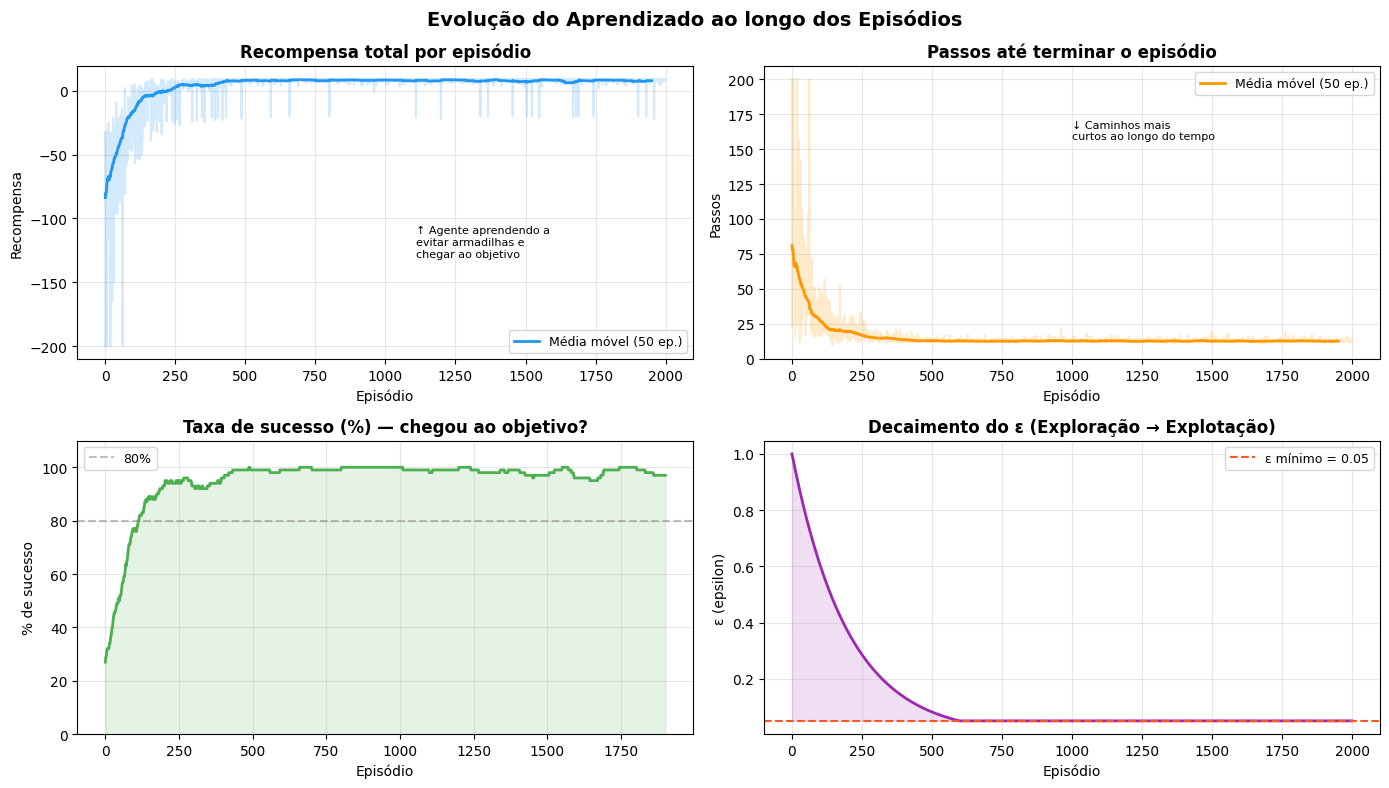

In [10]:
def media_movel(dados, janela=50):
    """Calcula a média móvel para suavizar os gráficos."""
    return np.convolve(dados, np.ones(janela) / janela, mode='valid')


fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle('Evolução do Aprendizado ao longo dos Episódios',
             fontsize=14, fontweight='bold')

# 1) Recompensa total
ax = axes[0, 0]
ax.plot(historico_recompensa, alpha=0.2, color='#2196F3')
ax.plot(media_movel(historico_recompensa), color='#2196F3', linewidth=2, label='Média móvel (50 ep.)')
ax.set_title('Recompensa total por episódio', fontweight='bold')
ax.set_xlabel('Episódio'); ax.set_ylabel('Recompensa')
ax.legend(fontsize=9); ax.grid(alpha=0.3)
ax.annotate('↑ Agente aprendendo a\nevitar armadilhas e\nchegar ao objetivo',
            xy=(0.55, 0.35), xycoords='axes fraction', fontsize=8)

# 2) Passos por episódio
ax = axes[0, 1]
ax.plot(historico_passos, alpha=0.2, color='#FF9800')
ax.plot(media_movel(historico_passos), color='#FF9800', linewidth=2, label='Média móvel (50 ep.)')
ax.set_title('Passos até terminar o episódio', fontweight='bold')
ax.set_xlabel('Episódio'); ax.set_ylabel('Passos')
ax.legend(fontsize=9); ax.grid(alpha=0.3)
ax.annotate('↓ Caminhos mais\ncurtos ao longo do tempo',
            xy=(0.5, 0.75), xycoords='axes fraction', fontsize=8)

# 3) Taxa de sucesso
ax = axes[1, 0]
taxa = media_movel(historico_sucesso, janela=100) * 100
ax.plot(taxa, color='#4CAF50', linewidth=2)
ax.fill_between(range(len(taxa)), taxa, alpha=0.15, color='#4CAF50')
ax.set_title('Taxa de sucesso (%) — chegou ao objetivo?', fontweight='bold')
ax.set_xlabel('Episódio'); ax.set_ylabel('% de sucesso')
ax.set_ylim(0, 110); ax.grid(alpha=0.3)
ax.axhline(80, color='gray', linestyle='--', alpha=0.5, label='80%')
ax.legend(fontsize=9)

# 4) Decaimento do epsilon
ax = axes[1, 1]
ax.plot(historico_epsilon, color='#9C27B0', linewidth=2)
ax.fill_between(range(len(historico_epsilon)), historico_epsilon,
                EPS_MIN, alpha=0.15, color='#9C27B0')
ax.axhline(EPS_MIN, color='#FF5722', linestyle='--', label=f'ε mínimo = {EPS_MIN}')
ax.set_title('Decaimento do ε (Exploração → Explotação)', fontweight='bold')
ax.set_xlabel('Episódio'); ax.set_ylabel('ε (epsilon)')
ax.legend(fontsize=9); ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

---
## 7. Política Aprendida — O que o Agente Aprendeu?

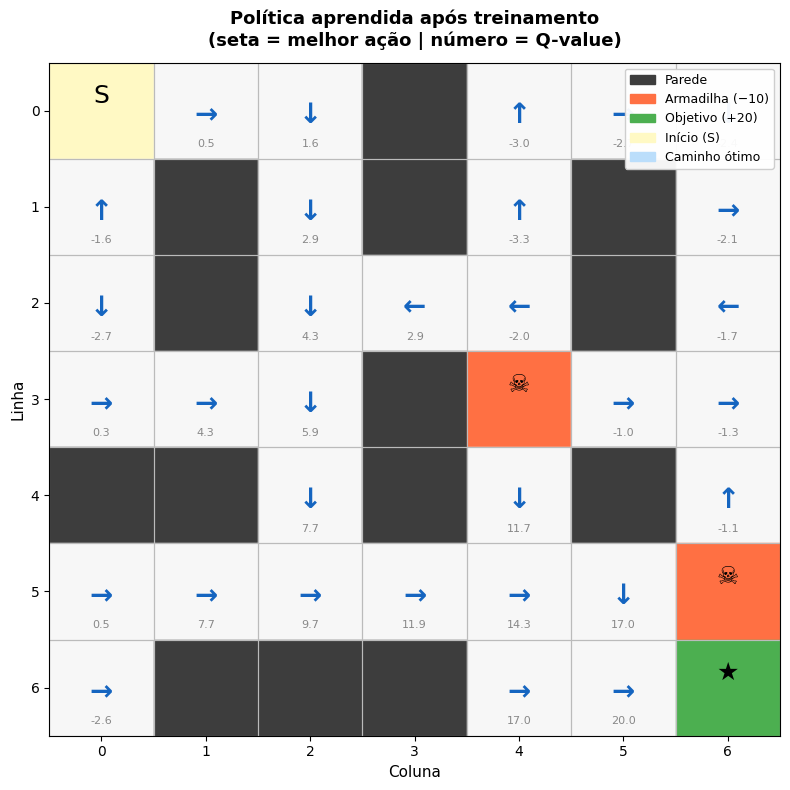

In [11]:
plot_maze(Q=Q, title='Política aprendida após treinamento\n(seta = melhor ação | número = Q-value)')

---
## 8. Simulando o Agente Treinado

Agora o agente usa **apenas a Q-table** (sem exploração) — ε = 0.

Simulando o agente treinado (sem exploração):
--------------------------------------------------
  Passo  1: (0, 0) →[→]→ (0, 1)  | r=-1  
  Passo  2: (0, 1) →[→]→ (0, 2)  | r=-1  
  Passo  3: (0, 2) →[↓]→ (1, 2)  | r=-1  
  Passo  4: (1, 2) →[↓]→ (2, 2)  | r=-1  
  Passo  5: (2, 2) →[↓]→ (3, 2)  | r=-1  
  Passo  6: (3, 2) →[↓]→ (4, 2)  | r=-1  
  Passo  7: (4, 2) →[↓]→ (5, 2)  | r=-1  
  Passo  8: (5, 2) →[→]→ (5, 3)  | r=-1  
  Passo  9: (5, 3) →[→]→ (5, 4)  | r=-1  
  Passo 10: (5, 4) →[→]→ (5, 5)  | r=-1  
  Passo 11: (5, 5) →[↓]→ (6, 5)  | r=-1  
  Passo 12: (6, 5) →[→]→ (6, 6)  | r=+20  ★ OBJETIVO!
--------------------------------------------------
Resultado: ✅ Chegou ao objetivo!
Passos: 12  |  Recompensa total: +9


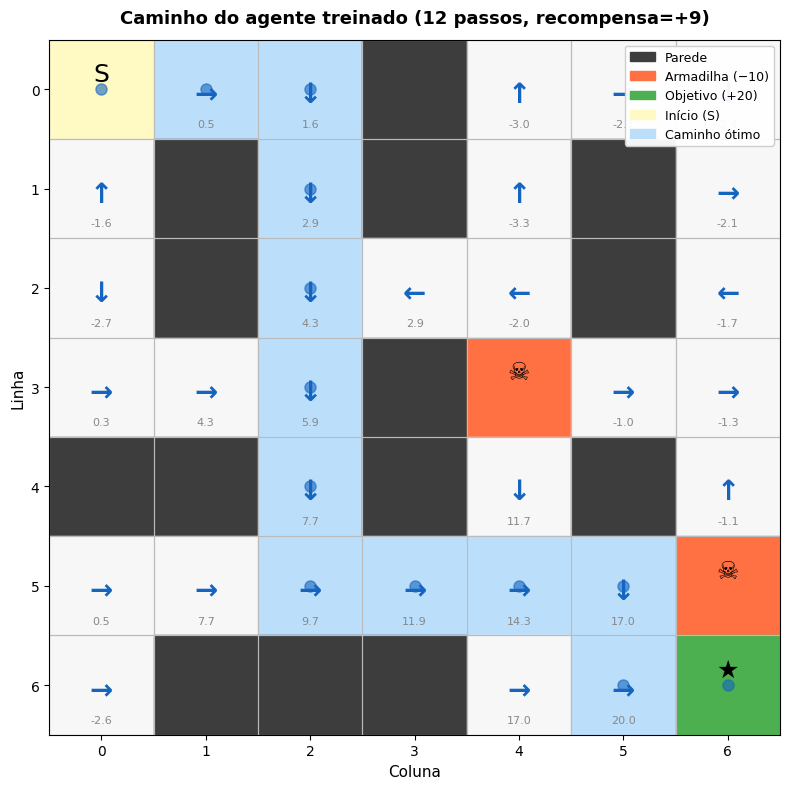

In [12]:
def simular_agente(Q, verbose=True):
    """Simula o agente usando a política aprendida (ε=0, sem exploração)."""
    state = START
    path  = [state]
    total_reward = 0

    if verbose:
        print('Simulando o agente treinado (sem exploração):')
        print('-' * 50)

    for step_n in range(50):
        r, c   = state
        action = int(np.argmax(Q[r, c]))
        next_state, reward, done = step(state, action)
        total_reward += reward
        path.append(next_state)

        if verbose:
            tipo = '☠ ARMADILHA!' if MAZE[next_state] == 2 else ('★ OBJETIVO!' if done and next_state == GOAL else '')
            print(f'  Passo {step_n+1:2d}: {state} →[{ACTION_ARROWS[action]}]→ {next_state}  | r={reward:+d}  {tipo}')

        state = next_state
        if done:
            break

    sucesso = (state == GOAL)
    if verbose:
        print('-' * 50)
        print(f'Resultado: {"✅ Chegou ao objetivo!" if sucesso else "❌ Não chegou"}')
        print(f'Passos: {len(path)-1}  |  Recompensa total: {total_reward:+d}')

    return path, sucesso, total_reward


caminho, sucesso, recompensa = simular_agente(Q)
plot_maze(Q=Q, path=caminho, title=f'Caminho do agente treinado ({len(caminho)-1} passos, recompensa={recompensa:+d})')

---
## 9. Assista: o agente antes, durante e depois do treino

Guardamos "fotos" da Q-table nos episódios 0, 100 e 300. Em cada painel o agente joga **um episódio** com a Q-table e o ε daquele momento do treino; no último, com a Q-table final e ε = 0.

> **Palpite:** no episódio 100 o ε ainda é ≈ 0,6. O agente já vai direto ao objetivo ou ainda passeia? Use os botões ⏮ ◀ ▶ para ir passo a passo.

In [13]:
# @title Funções de animação (rode e siga em frente)
from matplotlib import animation
from IPython.display import HTML


def animar(trajetorias, titulos, desenhar_fundo, xy, rotulo, max_quadros=60,
           intervalo=180, largura=3.4, altura=4.2, topo=0.78):
    """Anima as trajetórias lado a lado (uma por painel).

    trajetorias : lista de listas [(estado, recompensa_acumulada, evento), ...]
    Trajetórias longas são aceleradas (pulam passos) para caber em ~max_quadros quadros.
    """
    n = len(trajetorias)
    fig, axes = plt.subplots(1, n, figsize=(largura * n, altura), dpi=60)
    axes = np.atleast_1d(axes)
    pulo = [max(1, -(-len(t) // max_quadros)) for t in trajetorias]
    n_quadros = max(-(-len(t) // p) for t, p in zip(trajetorias, pulo)) + 6   # +6: pausa no fim
    paineis = []
    for ax, traj, tit in zip(axes, trajetorias, titulos):
        desenhar_fundo(ax)
        rastro, = ax.plot([], [], '-', color='#1565C0', alpha=0.35, lw=4, zorder=6)
        quedas, = ax.plot([], [], 'X', color='#B71C1C', ms=14, zorder=7)
        ponto, = ax.plot([], [], 'o', color='#1565C0', ms=13, mec='white', mew=2, zorder=8)
        titulo = ax.set_title(f'{tit}\n{rotulo(traj, 0)}', fontsize=11, fontweight='bold')
        paineis.append((traj, rastro, quedas, ponto, titulo, tit))
    fig.subplots_adjust(left=0.02, right=0.98, bottom=0.02, top=topo, wspace=0.08)

    def quadro(k):
        for (traj, rastro, quedas, ponto, titulo, tit), p in zip(paineis, pulo):
            i = min(k * p, len(traj) - 1)
            # o rastro recomeça a cada episódio novo e depois de cada queda (volta ao início)
            ini = max(j for j in range(i + 1) if j == 0 or traj[j][2] is not None)
            pts = [xy(e) for e, _, _ in traj[ini:i + 1]]
            rastro.set_data([x for x, _ in pts], [y for _, y in pts])
            ponto.set_data([pts[-1][0]], [pts[-1][1]])
            qx = [xy(ev[1]) for _, _, ev in traj[:i + 1] if isinstance(ev, tuple)]
            quedas.set_data([x for x, _ in qx], [y for _, y in qx])
            titulo.set_text(f'{tit}\n{rotulo(traj, i)}')
        return []

    anim = animation.FuncAnimation(fig, quadro, frames=n_quadros, interval=intervalo)
    plt.close(fig)
    return HTML(anim.to_jshtml(default_mode='once'))


def rodar_episodio(Q, epsilon, seed=0, max_passos=200):
    """Um episódio com ε-greedy usando a Q-table dada. Não altera a Q-table."""
    rng = random.Random(seed)
    estado, total = START, 0
    traj = [(estado, 0, None)]
    for _ in range(max_passos):
        a = rng.choice(ACTIONS) if rng.random() < epsilon else int(np.argmax(Q[estado]))
        estado, r, done = step(estado, a)
        total += r
        traj.append((estado, total, None))
        if done:
            break
    return traj


def _fundo_labirinto(ax):
    cores = {0: '#f7f7f7', 1: '#3d3d3d', 2: '#FF7043', 3: '#4CAF50'}
    for r in range(ROWS):
        for c in range(COLS):
            cor = '#FFF9C4' if (r, c) == START else cores[MAZE[r, c]]
            ax.add_patch(plt.Rectangle((c, ROWS - r - 1), 1, 1, facecolor=cor, edgecolor='#bbbbbb', lw=0.8))
            icone = 'S' if (r, c) == START else {2: '☠', 3: '★'}.get(MAZE[r, c], '')
            if icone:
                ax.text(c + 0.5, ROWS - r - 0.5, icone, ha='center', va='center', fontsize=14, alpha=0.7)
    ax.set_xlim(0, COLS); ax.set_ylim(0, ROWS); ax.set_aspect('equal'); ax.axis('off')


def _rotulo_labirinto(traj, i):
    estado, total, _ = traj[i]
    fim = 'em andamento…'
    if i == len(traj) - 1:
        fim = '★ chegou!' if estado == GOAL else ('☠ caiu na armadilha' if MAZE[estado] == 2 else 'limite de passos')
    return f'passo {i} | recompensa {total:+d}\n{fim}'


def animar_labirinto(trajetorias, titulos):
    return animar(trajetorias, titulos, _fundo_labirinto,
                  xy=lambda e: (e[1] + 0.5, ROWS - e[0] - 0.5), rotulo=_rotulo_labirinto)

In [14]:
trajetorias, titulos = [], []
for ep, (Q_ep, eps_ep) in Q_fotos.items():
    trajetorias.append(rodar_episodio(Q_ep, eps_ep, seed=3))
    titulos.append(f'Episódio {ep} (ε = {eps_ep:.2f})')
trajetorias.append(rodar_episodio(Q, 0.0))
titulos.append('Depois do treino (ε = 0)')

animar_labirinto(trajetorias, titulos)

**Para pensar**
1. No episódio 0 a Q-table é toda zero e ε = 1: o agente anda ao acaso. Quantos passos ele levaria, em média, para achar o objetivo por sorte?
2. Entre o episódio 100 e o 300, o que mudou mais: a Q-table ou o ε? Como separar os dois efeitos? (dica: rode `rodar_episodio(Q_fotos[300][0], 0.0)`)
3. Troque `seed=3` por outros valores. O comportamento do episódio 100 muda muito de uma semente para outra? Por quê?

---
## 10. Inspecionando a Q-table

Vamos olhar de perto os valores aprendidos para alguns estados:

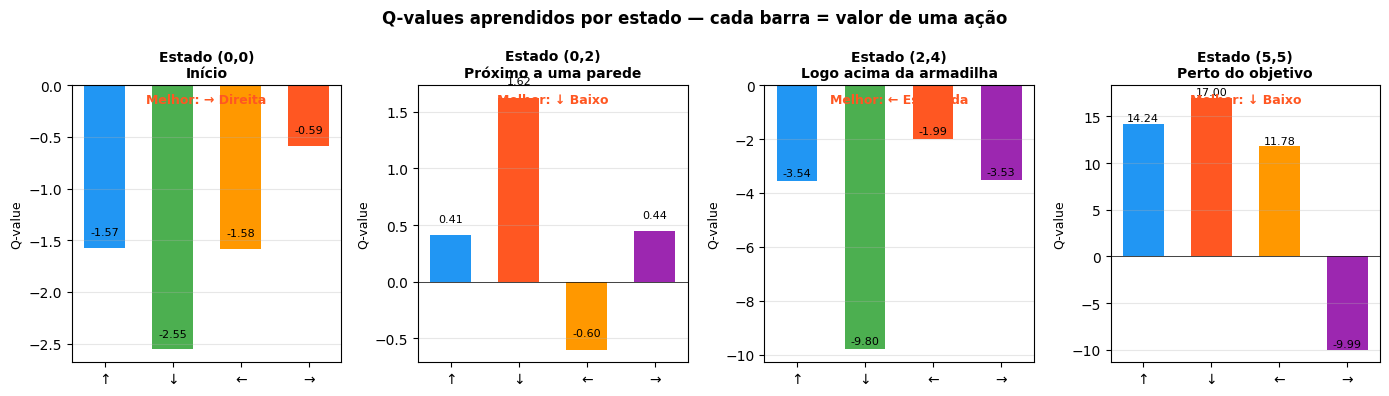


Observação: a barra laranja é a ação escolhida pela política ótima em cada estado.


In [15]:
estados_interesse = [
    (0, 0, 'Início'),
    (0, 2, 'Próximo a uma parede'),
    (2, 4, 'Logo acima da armadilha'),
    (5, 5, 'Perto do objetivo'),
]

fig, axes = plt.subplots(1, len(estados_interesse), figsize=(14, 4))
fig.suptitle('Q-values aprendidos por estado — cada barra = valor de uma ação',
             fontsize=12, fontweight='bold')

cores_acao = ['#2196F3', '#4CAF50', '#FF9800', '#9C27B0']

for ax, (r, c, nome) in zip(axes, estados_interesse):
    q_vals = Q[r, c]
    melhor = int(np.argmax(q_vals))
    cores  = [cores_acao[i] if i != melhor else '#FF5722' for i in range(4)]

    bars = ax.bar([ACTION_ARROWS[i] for i in ACTIONS], q_vals, color=cores, width=0.6)
    ax.set_title(f'Estado ({r},{c})\n{nome}', fontsize=10, fontweight='bold')
    ax.set_ylabel('Q-value', fontsize=9)
    ax.axhline(0, color='black', linewidth=0.5)
    ax.grid(axis='y', alpha=0.3)

    # Anota o valor em cada barra
    for bar, val in zip(bars, q_vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                f'{val:.2f}', ha='center', va='bottom', fontsize=8)

    # Destaca a melhor ação
    ax.text(0.5, 0.97, f'Melhor: {ACTION_ARROWS[melhor]} {ACTION_NAMES[melhor]}',
            transform=ax.transAxes, ha='center', va='top',
            fontsize=9, color='#FF5722', fontweight='bold')

plt.tight_layout()
plt.show()

print('\nObservação: a barra laranja é a ação escolhida pela política ótima em cada estado.')

---
## 11. Experimento — O impacto dos Hiperparâmetros (slide 106)

Em duplas: **antes de rodar, escrevam o palpite.**

| Desafio | Teste | Observe |
|---|---|---|
| 1 · Mexa no α | α = 0,1, 0,5 e 0,9 | velocidade e estabilidade |
| 2 · Mexa no γ | γ = 0,5, 0,9 e 0,99 | o agente fica míope? |
| 3 · Mexa no ε | ε fixo × ε decaindo | quando para de explorar |

Cada curva é a média de **3 sementes** (slide 138: um único treino não prova nada).

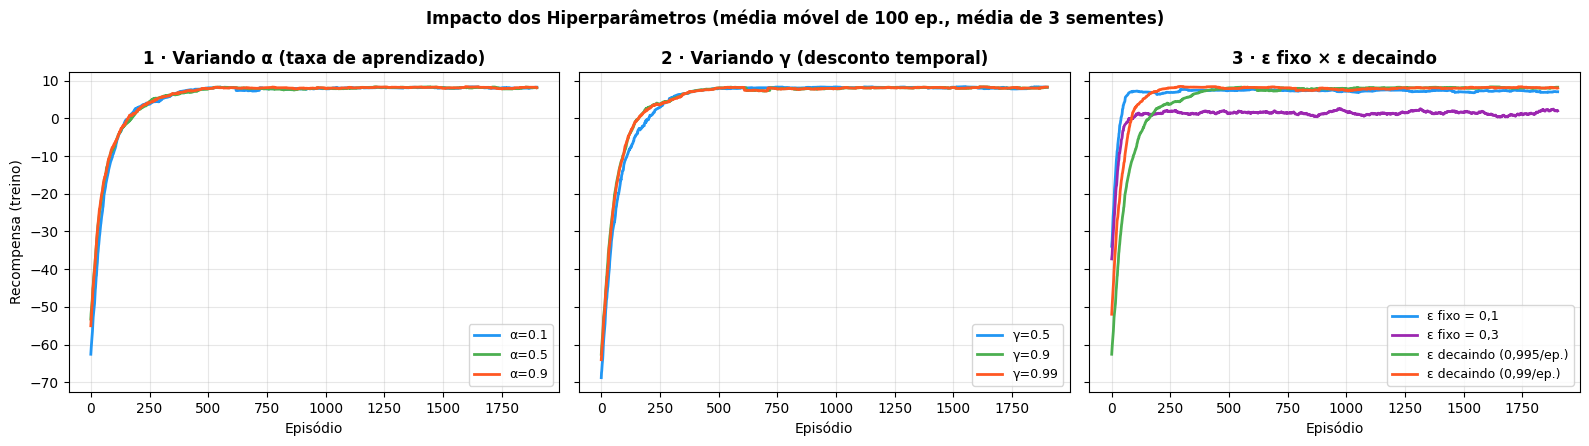

In [16]:
def treinar(alpha, gamma, eps_decay, eps_inicial=1.0, n_ep=2000, seed=42):
    '''Treina o agente com os hiperparâmetros dados e retorna o histórico de recompensa.
    eps_decay = 1.0 mantém o ε fixo em eps_inicial.'''
    random.seed(seed); np.random.seed(seed)
    Q_loc = np.zeros((ROWS, COLS, len(ACTIONS)))
    eps   = eps_inicial
    hist  = []

    for _ in range(n_ep):
        state = START
        total = 0
        for _ in range(MAX_STEPS):
            action = choose_action(state, Q_loc, eps)
            next_state, reward, done = step(state, action)
            atualizar_q(Q_loc, state, action, reward, next_state, done, alpha, gamma)
            total += reward; state = next_state
            if done: break
        eps = max(EPS_MIN, eps * eps_decay)
        hist.append(total)
    return hist


def curva(sementes=(0, 1, 2), **kw):
    '''Média móvel (100 ep.) da recompensa, na média de várias sementes.'''
    return np.mean([media_movel(treinar(seed=s, **kw), 100) for s in sementes], axis=0)


fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
fig.suptitle('Impacto dos Hiperparâmetros (média móvel de 100 ep., média de 3 sementes)',
             fontsize=12, fontweight='bold')

# 1 · α (taxa de aprendizado)
ax = axes[0]
for alpha_val, cor in [(0.1, '#2196F3'), (0.5, '#4CAF50'), (0.9, '#FF5722')]:
    ax.plot(curva(alpha=alpha_val, gamma=0.9, eps_decay=0.995), label=f'α={alpha_val}', color=cor, linewidth=2)
ax.set_title('1 · Variando α (taxa de aprendizado)', fontweight='bold')

# 2 · γ (desconto)
ax = axes[1]
for gamma_val, cor in [(0.5, '#2196F3'), (0.9, '#4CAF50'), (0.99, '#FF5722')]:
    ax.plot(curva(alpha=0.1, gamma=gamma_val, eps_decay=0.995), label=f'γ={gamma_val}', color=cor, linewidth=2)
ax.set_title('2 · Variando γ (desconto temporal)', fontweight='bold')

# 3 · ε fixo × ε decaindo
ax = axes[2]
for rotulo, kw, cor in [('ε fixo = 0,1',              dict(eps_inicial=0.1, eps_decay=1.0),   '#2196F3'),
                        ('ε fixo = 0,3',              dict(eps_inicial=0.3, eps_decay=1.0),   '#9C27B0'),
                        ('ε decaindo (0,995/ep.)',    dict(eps_inicial=1.0, eps_decay=0.995), '#4CAF50'),
                        ('ε decaindo (0,99/ep.)',     dict(eps_inicial=1.0, eps_decay=0.99),  '#FF5722')]:
    ax.plot(curva(alpha=0.1, gamma=0.9, **kw), label=rotulo, color=cor, linewidth=2)
ax.set_title('3 · ε fixo × ε decaindo', fontweight='bold')

for ax in axes:
    ax.set_xlabel('Episódio')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Recompensa (treino)')
plt.tight_layout()
plt.show()

---
## 12. Resumo — Q-Learning em 5 pontos

| # | Conceito | O que vimos |
|---|---|---|
| 1 | **Q-table** | Tabela Q(s,a): qual ação tem maior valor em cada estado |
| 2 | **ε-greedy** | Equilíbrio entre explorar (aprender) e explotar (ganhar) |
| 3 | **Equação de Bellman** | Como atualizar Q a cada experiência nova |
| 4 | **Convergência** | Após muitos episódios, a política estabiliza |
| 5 | **Hiperparâmetros** | α, γ e ε-decay afetam velocidade e qualidade do aprendizado |

### Por que Q-Learning é poderoso?

- **Model-free**: não precisa conhecer o ambiente antecipadamente
- **Off-policy**: aprende a política ótima enquanto explora
- **Garantia teórica**: converge para a política ótima (com condições suficientes)

### Limitação: curse of dimensionality

A Q-table tem tamanho `|S| × |A|`. Para ambientes complexos (jogos de vídeo, robótica), o espaço de estados é enorme — e aí entra o **Deep Q-Network (DQN)**: substitui a Q-table por uma rede neural! 🚀

In [17]:
# Dimensão da Q-table neste exemplo
print('=== Tamanho da Q-table ===')
print(f'  Estados  : {ROWS} × {COLS} = {ROWS*COLS}')
print(f'  Ações    : {len(ACTIONS)}')
print(f'  Total    : {ROWS * COLS * len(ACTIONS)} valores')
print()
print('E se o ambiente fosse um jogo de Atari?')
atari_states = 210 * 160 * 3  # pixels RGB
print(f'  Pixels de uma tela Atari: 210×160×3 = {atari_states:,}')
print(f'  Estados possíveis: 256^{atari_states} → impossível para uma tabela!')
print()
print('→ Solução: Deep Q-Network (DQN) — a rede neural aprende a Q-function!')

=== Tamanho da Q-table ===
  Estados  : 7 × 7 = 49
  Ações    : 4
  Total    : 196 valores

E se o ambiente fosse um jogo de Atari?
  Pixels de uma tela Atari: 210×160×3 = 100,800
  Estados possíveis: 256^100800 → impossível para uma tabela!

→ Solução: Deep Q-Network (DQN) — a rede neural aprende a Q-function!
